In [1]:
!pip -q install scikit-learn matplotlib seaborn kaggle

In [2]:
from google.colab import files
print("Faça o upload do seu arquivo kaggle.json:")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("Autenticação configurada.")

Faça o upload do seu arquivo kaggle.json:


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Autenticação configurada.


In [3]:
import os
import random
import copy
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score
)

SEED = 12

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda
GPU: Tesla T4


In [4]:
DATA_DIR = "/content/data"

os.makedirs(DATA_DIR, exist_ok=True)

!kaggle datasets download \
    -d tawsifurrahman/covid19-radiography-database \
    -p /content/data \
    --unzip

print("Download e extração concluídos.")

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
100% 778M/778M [00:46<00:00, 17.5MB/s]

Download e extração concluídos.


In [5]:
from pathlib import Path

for path in list(Path("/content/data").iterdir())[:20]:
    print(path)

/content/data/COVID-19_Radiography_Dataset


In [8]:
DATASET_PATH = "/content/data/COVID-19_Radiography_Dataset"

# Ajustado para corresponder exatamente às pastas físicas do dataset baixado
CLASS_NAMES = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
COVID_NAME = "COVID"
COVID_IDX = CLASS_NAMES.index(COVID_NAME)

IMAGE_SIZE = 224
GAN_SIZE = 64
BATCH_SIZE = 32

# Imagens de treinamento para a CNN.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Sem augmentation aleatória para validação e teste.
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset base para identificar arquivos e rótulos.
base_dataset = datasets.ImageFolder(DATASET_PATH)

assert base_dataset.classes == CLASS_NAMES, (
    f"Classes encontradas: {base_dataset.classes}. "
    f"Esperadas: {CLASS_NAMES}. Ajuste CLASS_NAMES."
)

targets = np.array(base_dataset.targets)
indices = np.arange(len(targets))

# 20% para teste.
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=targets,
    random_state=SEED
)

# 20% do conjunto total para validação.
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,
    stratify=targets[train_val_idx],
    random_state=SEED
)

# Instâncias separadas garantem transformações apropriadas.
train_dataset = datasets.ImageFolder(
    DATASET_PATH, transform=train_transform
)
eval_dataset = datasets.ImageFolder(
    DATASET_PATH, transform=eval_transform
)

train_subset = Subset(train_dataset, train_idx)
val_subset = Subset(eval_dataset, val_idx)
test_subset = Subset(eval_dataset, test_idx)

train_loader = DataLoader(
    train_subset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_subset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_subset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

def show_distribution(name, idx):
    counts = Counter(targets[idx])
    print(name, {
        CLASS_NAMES[i]: counts.get(i, 0)
        for i in range(len(CLASS_NAMES))
    })

show_distribution("Treinamento", train_idx)
show_distribution("Validação", val_idx)
show_distribution("Teste", test_idx)

print("Total de imagens:", len(base_dataset))

Treinamento {'COVID': 4340, 'Lung_Opacity': 7214, 'Normal': 12230, 'Viral Pneumonia': 1614}
Validação {'COVID': 1446, 'Lung_Opacity': 2405, 'Normal': 4077, 'Viral Pneumonia': 538}
Teste {'COVID': 1446, 'Lung_Opacity': 2405, 'Normal': 4077, 'Viral Pneumonia': 538}
Total de imagens: 42330


In [9]:
gan_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((GAN_SIZE, GAN_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

gan_dataset = datasets.ImageFolder(
    DATASET_PATH,
    transform=gan_transform
)

gan_train_subset = Subset(gan_dataset, train_idx)

gan_loader = DataLoader(
    gan_train_subset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

In [10]:
gan_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((GAN_SIZE, GAN_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

gan_dataset = datasets.ImageFolder(
    DATASET_PATH,
    transform=gan_transform
)

gan_train_subset = Subset(gan_dataset, train_idx)

gan_loader = DataLoader(
    gan_train_subset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

In [11]:
NUM_CLASSES = len(CLASS_NAMES)
LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.label_embedding = nn.Embedding(
            NUM_CLASSES, NUM_CLASSES
        )

        self.fc = nn.Sequential(
            nn.Linear(
                LATENT_DIM + NUM_CLASSES, 256 * 8 * 8
            ),
            nn.BatchNorm1d(256 * 8 * 8),
            nn.ReLU(True)
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1, 4, 2, 1, bias=False
            ),
            nn.Tanh()
        )

    def forward(self, z, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([z, label_vec], dim=1)
        x = self.fc(x)
        x = x.view(-1, 256, 8, 8)
        return self.net(x)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.label_embedding = nn.Embedding(
            NUM_CLASSES, GAN_SIZE * GAN_SIZE
        )

        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 8 * 8, 1)
        )

    def forward(self, images, labels):
        label_map = self.label_embedding(labels)
        label_map = label_map.view(
            -1, 1, GAN_SIZE, GAN_SIZE
        )
        x = torch.cat([images, label_map], dim=1)
        return self.net(x)


generator = Generator().to(device)
discriminator = Discriminator().to(device)

criterion_gan = nn.BCEWithLogitsLoss()

optimizer_g = optim.Adam(
    generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
optimizer_d = optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

print("GAN e discriminador inicializados.")

GAN e discriminador inicializados.


In [12]:
GAN_EPOCHS = 30

for epoch in range(GAN_EPOCHS):
    generator.train()
    discriminator.train()

    loss_g_sum = 0.0
    loss_d_sum = 0.0

    for real_images, labels in gan_loader:
        real_images = real_images.to(device)
        labels = labels.to(device)
        batch_size = real_images.size(0)

        real_targets = torch.ones(
            batch_size, 1, device=device
        ) * 0.9

        fake_targets = torch.zeros(
            batch_size, 1, device=device
        )

        # Treina o discriminador.
        optimizer_d.zero_grad()

        real_logits = discriminator(real_images, labels)
        loss_real = criterion_gan(
            real_logits, real_targets
        )

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = generator(z, labels)

        fake_logits = discriminator(
            fake_images.detach(), labels
        )
        loss_fake = criterion_gan(
            fake_logits, fake_targets
        )

        loss_d = loss_real + loss_fake
        loss_d.backward()
        optimizer_d.step()

        # Treina o gerador.
        optimizer_g.zero_grad()

        z = torch.randn(batch_size, LATENT_DIM, device=device)
        generated = generator(z, labels)

        generated_logits = discriminator(generated, labels)
        loss_g = criterion_gan(
            generated_logits, torch.ones_like(generated_logits)
        )

        loss_g.backward()
        optimizer_g.step()

        loss_d_sum += loss_d.item()
        loss_g_sum += loss_g.item()

    print(
        f"Época {epoch + 1:02d}/{GAN_EPOCHS} | "
        f"D: {loss_d_sum / len(gan_loader):.4f} | "
        f"G: {loss_g_sum / len(gan_loader):.4f}"
    )

os.makedirs("/content/checkpoints", exist_ok=True)

torch.save(
    generator.state_dict(),
    "/content/checkpoints/cgan_generator.pth"
)

Época 01/30 | D: 0.6701 | G: 2.8065
Época 02/30 | D: 0.8668 | G: 1.9600
Época 03/30 | D: 0.8373 | G: 2.2220
Época 04/30 | D: 0.8039 | G: 2.2342
Época 05/30 | D: 0.6921 | G: 2.7791
Época 06/30 | D: 0.7601 | G: 2.4207
Época 07/30 | D: 0.7145 | G: 2.7115
Época 08/30 | D: 0.7089 | G: 2.8113
Época 09/30 | D: 0.6350 | G: 3.1352
Época 10/30 | D: 0.6446 | G: 3.2238
Época 11/30 | D: 0.6558 | G: 3.0113
Época 12/30 | D: 0.6897 | G: 2.9840
Época 13/30 | D: 0.6755 | G: 3.1034
Época 14/30 | D: 0.6469 | G: 3.0777
Época 15/30 | D: 0.6027 | G: 3.4264
Época 16/30 | D: 0.6358 | G: 3.3176
Época 17/30 | D: 0.6295 | G: 3.2207
Época 18/30 | D: 0.6923 | G: 3.0713
Época 19/30 | D: 0.5794 | G: 3.4601
Época 20/30 | D: 0.6301 | G: 3.2238
Época 21/30 | D: 0.6010 | G: 3.3042
Época 22/30 | D: 0.6575 | G: 3.0910
Época 23/30 | D: 0.6025 | G: 3.4553
Época 24/30 | D: 0.5629 | G: 3.5936
Época 25/30 | D: 0.5699 | G: 3.7514
Época 26/30 | D: 0.5922 | G: 3.5622
Época 27/30 | D: 0.5863 | G: 3.7895
Época 28/30 | D: 0.5871 | G:

In [18]:
# Quantidade de imagens COVID-19 no treinamento.
train_counts = Counter(targets[train_idx])
real_covid_count = train_counts[COVID_IDX]

TARGET_COVID_COUNT = 5000
NUM_SYNTHETIC = max(
    0, TARGET_COVID_COUNT - real_covid_count
)

print("COVID-19 real no treino:", real_covid_count)
print("Imagens sintéticas a gerar:", NUM_SYNTHETIC)

generator.eval()

synthetic_dir = Path("/content/synthetic/COVID-19")
synthetic_dir.mkdir(parents=True, exist_ok=True)

# Limpa imagens de execuções anteriores.
for path in synthetic_dir.glob("*.png"):
    path.unlink()

with torch.no_grad():
    for start in range(0, NUM_SYNTHETIC, 64):
        n = min(64, NUM_SYNTHETIC - start)

        z = torch.randn(n, LATENT_DIM, device=device)
        labels = torch.full(
            (n,), COVID_IDX, dtype=torch.long, device=device
        )

        fake = generator(z, labels)

        # Converte de [-1, 1] para [0, 1].
        fake = (fake + 1) / 2

        for j in range(n):
            save_image(
                fake[j],
                synthetic_dir / f"covid_{start + j:04d}.png"
            )

print("Imagens sintéticas salvas em:", synthetic_dir)

COVID-19 real no treino: 4340
Imagens sintéticas a gerar: 660
Imagens sintéticas salvas em: /content/synthetic/COVID-19


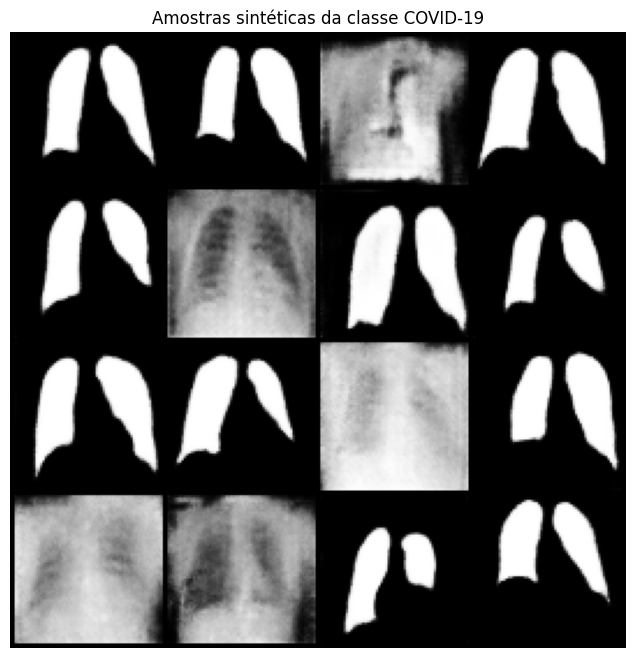

In [19]:
from PIL import Image

files = sorted(synthetic_dir.glob("*.png"))[:16]

if files:
    images = [
        transforms.ToTensor()(
            Image.open(f).convert("L")
        )
        for f in files
    ]

    grid = make_grid(images, nrow=4, normalize=True)

    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title("Amostras sintéticas da classe COVID-19")
    plt.axis("off")
    plt.show()
else:
    print("Nenhuma imagem sintética foi necessária.")

In [20]:
from torch.utils.data import ConcatDataset

class SyntheticCovidDataset(Dataset):
    def __init__(self, directory, transform):
        self.files = sorted(Path(directory).glob("*.png"))
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        image = Image.open(self.files[idx]).convert("RGB")
        image = self.transform(image)
        return image, COVID_IDX


synthetic_dataset = SyntheticCovidDataset(
    synthetic_dir, train_transform
)

# Experimento A: somente imagens reais.
dataset_real = train_subset

# Experimento B: imagens reais + imagens sintéticas.
dataset_augmented = ConcatDataset([
    train_subset,
    synthetic_dataset
])

def make_train_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2
    )

loader_real = make_train_loader(dataset_real)
loader_augmented = make_train_loader(dataset_augmented)

print("Imagens reais:", len(dataset_real))
print("Imagens sintéticas:", len(synthetic_dataset))
print("Total no experimento B:", len(dataset_augmented))

Imagens reais: 25398
Imagens sintéticas: 660
Total no experimento B: 26058


In [21]:
def create_model():
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )
    model.fc = nn.Linear(
        model.fc.in_features, NUM_CLASSES
    )
    return model.to(device)


def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()

            y_pred.extend(preds)
            y_true.extend(labels.numpy())

    covid_recall = recall_score(
        y_true, y_pred,
        labels=[COVID_IDX],
        average=None,
        zero_division=0
    )[0]

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "covid_recall": covid_recall,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred)
    }


def train_classifier(train_loader, val_loader, epochs=8):
    model = create_model()

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        model.parameters(), lr=0.0001, weight_decay=1e-4
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    best_recall = -1
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        val_metrics = evaluate(model, val_loader)
        val_recall = val_metrics["covid_recall"]

        scheduler.step(val_recall)

        history.append({
            "epoch": epoch + 1,
            "train_loss": running_loss / len(train_loader),
            "val_accuracy": val_metrics["accuracy"],
            "val_covid_recall": val_recall
        })

        print(
            f"Época {epoch+1}/{epochs} | "
            f"Loss: {running_loss / len(train_loader):.4f} | "
            f"Val accuracy: {val_metrics['accuracy']:.4f} | "
            f"Val recall COVID: {val_recall:.4f}"
        )

        if val_recall > best_recall:
            best_recall = val_recall
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, history

In [22]:
# Reinicialização controlada para reduzir diferenças aleatórias.
def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


reset_seed()
model_real, history_real = train_classifier(
    loader_real, val_loader, epochs=8
)

reset_seed()
model_synthetic, history_synthetic = train_classifier(
    loader_augmented, val_loader, epochs=8
)

Época 1/8 | Loss: 0.5236 | Val accuracy: 0.8440 | Val recall COVID: 0.6957
Época 2/8 | Loss: 0.4059 | Val accuracy: 0.8525 | Val recall COVID: 0.7026
Época 3/8 | Loss: 0.3682 | Val accuracy: 0.8528 | Val recall COVID: 0.7531
Época 4/8 | Loss: 0.3382 | Val accuracy: 0.8545 | Val recall COVID: 0.7490
Época 5/8 | Loss: 0.3193 | Val accuracy: 0.8577 | Val recall COVID: 0.7130
Época 6/8 | Loss: 0.2902 | Val accuracy: 0.8555 | Val recall COVID: 0.7448
Época 7/8 | Loss: 0.2345 | Val accuracy: 0.8623 | Val recall COVID: 0.7766
Época 8/8 | Loss: 0.2089 | Val accuracy: 0.8672 | Val recall COVID: 0.7704
Época 1/8 | Loss: 0.5091 | Val accuracy: 0.8267 | Val recall COVID: 0.7102
Época 2/8 | Loss: 0.3938 | Val accuracy: 0.8365 | Val recall COVID: 0.6542
Época 3/8 | Loss: 0.3616 | Val accuracy: 0.8490 | Val recall COVID: 0.6667
Época 4/8 | Loss: 0.3314 | Val accuracy: 0.8409 | Val recall COVID: 0.5781
Época 5/8 | Loss: 0.2817 | Val accuracy: 0.8684 | Val recall COVID: 0.7690
Época 6/8 | Loss: 0.2521 

In [23]:
metrics_real = evaluate(model_real, test_loader)
metrics_synthetic = evaluate(model_synthetic, test_loader)

def summarize(model_name, metrics):
    y_true = metrics["y_true"]
    y_pred = metrics["y_pred"]

    return {
        "Modelo": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall COVID-19": recall_score(
            y_true, y_pred,
            labels=[COVID_IDX], average=None,
            zero_division=0
        )[0],
        "Precision COVID-19": precision_score(
            y_true, y_pred,
            labels=[COVID_IDX], average=None,
            zero_division=0
        )[0],
        "F1 COVID-19": f1_score(
            y_true, y_pred,
            labels=[COVID_IDX], average=None,
            zero_division=0
        )[0],
        "Recall macro": recall_score(
            y_true, y_pred,
            average="macro", zero_division=0
        )
    }


import pandas as pd

results = pd.DataFrame([
    summarize("Somente imagens reais", metrics_real),
    summarize("Imagens reais + sintéticas", metrics_synthetic)
])

display(results.round(4))

delta_recall = (
    metrics_synthetic["covid_recall"]
    - metrics_real["covid_recall"]
)

print(f"Variação absoluta do recall COVID-19: {delta_recall:+.4f}")
print(f"Variação em pontos percentuais: {delta_recall * 100:+.2f} p.p.")

,Modelo,Accuracy,Recall COVID-19,Precision COVID-19,F1 COVID-19,Recall macro
0,Somente imagens reais,0.8685,0.7711,0.8022,0.7863,0.8653
1,Imagens reais + sintéticas,0.8744,0.7822,0.8154,0.7984,0.8700


Variação absoluta do recall COVID-19: +0.0111
Variação em pontos percentuais: +1.11 p.p.


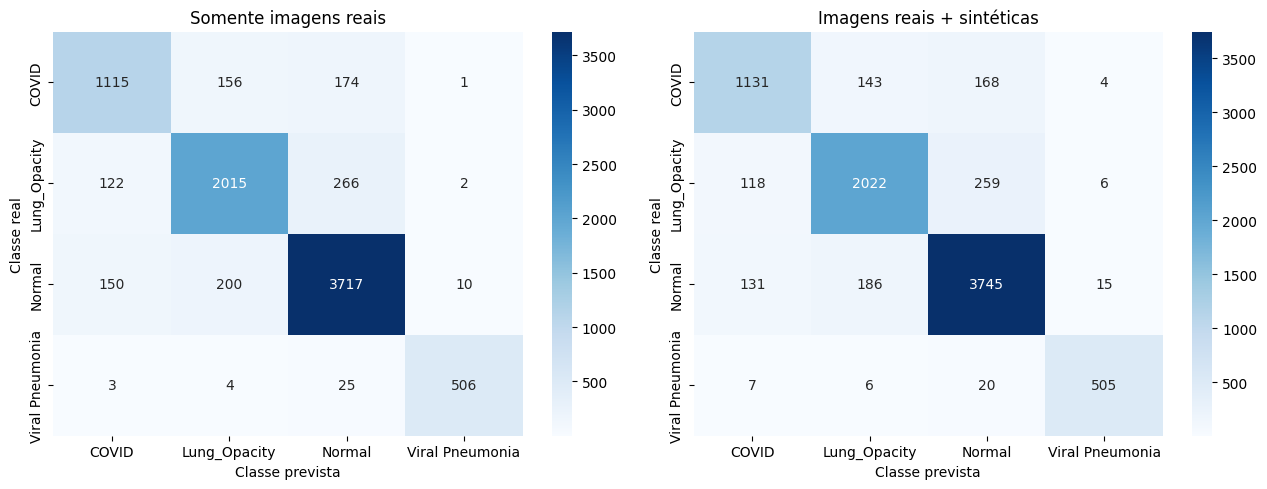

=== Somente imagens reais ===
                 precision    recall  f1-score   support

          COVID       0.80      0.77      0.79      1446
   Lung_Opacity       0.85      0.84      0.84      2405
         Normal       0.89      0.91      0.90      4077
Viral Pneumonia       0.97      0.94      0.96       538

       accuracy                           0.87      8466
      macro avg       0.88      0.87      0.87      8466
   weighted avg       0.87      0.87      0.87      8466

=== Imagens reais + sintéticas ===
                 precision    recall  f1-score   support

          COVID       0.82      0.78      0.80      1446
   Lung_Opacity       0.86      0.84      0.85      2405
         Normal       0.89      0.92      0.91      4077
Viral Pneumonia       0.95      0.94      0.95       538

       accuracy                           0.87      8466
      macro avg       0.88      0.87      0.87      8466
   weighted avg       0.87      0.87      0.87      8466



In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metrics, title in [
    (axes[0], metrics_real, "Somente imagens reais"),
    (axes[1], metrics_synthetic, "Imagens reais + sintéticas")
]:
    cm = confusion_matrix(
        metrics["y_true"],
        metrics["y_pred"],
        labels=list(range(NUM_CLASSES))
    )

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

plt.tight_layout()
plt.show()

print("=== Somente imagens reais ===")
print(classification_report(
    metrics_real["y_true"],
    metrics_real["y_pred"],
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("=== Imagens reais + sintéticas ===")
print(classification_report(
    metrics_synthetic["y_true"],
    metrics_synthetic["y_pred"],
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))